# Esteira de Aprendizado de Máquina — Classificação de Espécies de Pinguins

**Dataset:** [Palmer Penguins (Kaggle)](https://www.kaggle.com/datasets/ashkhagan/palmer-penguins-datasetalternative-iris-dataset)

**Problema:** classificação supervisionada (3 classes: `Adelie`, `Chinstrap`, `Gentoo`).

Este notebook implementa a esteira completa exigida na atividade:

1. Carga e estatísticas descritivas gerais da base.
2. Transformação em **colunas** (engenharia de atributo + codificação + escalonamento).
3. Transformação em **linhas** (remoção de registros incompletos e duplicados).
4. Divisão estratificada em **treino (60%)**, **validação (20%)** e **teste (20%)**.
5. Treinamento de modelos e escolha na base de validação.
6. Matriz de confusão e acurácia no conjunto de teste.
7. Serialização do modelo e predição com o modelo **implantado** (carregado do disco).

In [1]:
from pathlib import Path
import io
import urllib.request
import zipfile

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

print(f"pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

pandas 2.3.3 | scikit-learn 1.9.1


## 1. Carga do conjunto de dados

O arquivo `data/penguins.csv` acompanha o repositório. Caso ele não exista, o notebook faz o download direto da API pública do Kaggle, deixando a execução reproduzível sem credenciais.

In [2]:
DATA_PATH = Path("data/penguins.csv")
KAGGLE_URL = "https://www.kaggle.com/api/v1/datasets/download/ashkhagan/palmer-penguins-datasetalternative-iris-dataset"

if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    with urllib.request.urlopen(KAGGLE_URL, timeout=60) as resposta:
        conteudo = zipfile.ZipFile(io.BytesIO(resposta.read()))
    conteudo.extract("penguins.csv", DATA_PATH.parent)
    (DATA_PATH.parent / "penguins.csv").rename(DATA_PATH)

df = pd.read_csv(DATA_PATH, na_values=["NA", ""])
print(f"Arquivo: {DATA_PATH} | registros: {len(df)} | colunas: {len(df.columns)}")
df.head()

Arquivo: data/penguins.csv | registros: 344 | colunas: 7


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female


## 2. Estatísticas descritivas gerais

Analisamos formato, tipos, valores ausentes, distribuição das classes e resumo numérico/categórico da base original.

In [3]:
print("Formato (linhas, colunas):", df.shape)
df.info()

Formato (linhas, colunas): (344, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [4]:
descritivo = df.describe(include="all").T
display(descritivo)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
species,344,3,Adelie,152,NaN,NaN,NaN,NaN,NaN,NaN,NaN
island,344,3,Biscoe,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bill_length_mm,342.0,NaN,NaN,NaN,43.92193,5.459584,32.1,39.225,44.45,48.5,59.6
bill_depth_mm,342.0,NaN,NaN,NaN,17.15117,1.974793,13.1,15.6,17.3,18.7,21.5
flipper_length_mm,342.0,NaN,NaN,NaN,200.915205,14.061714,172.0,190.0,197.0,213.0,231.0
body_mass_g,342.0,NaN,NaN,NaN,4201.754386,801.954536,2700.0,3550.0,4050.0,4750.0,6300.0
sex,333,2,male,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
print("Valores ausentes por coluna:")
display(df.isna().sum().to_frame("quantidade"))

print("Distribuição das espécies:")
display(df["species"].value_counts().to_frame("quantidade"))

Valores ausentes por coluna:


,quantidade
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11


Distribuição das espécies:


,quantidade
species,
Adelie,152
Gentoo,124
Chinstrap,68


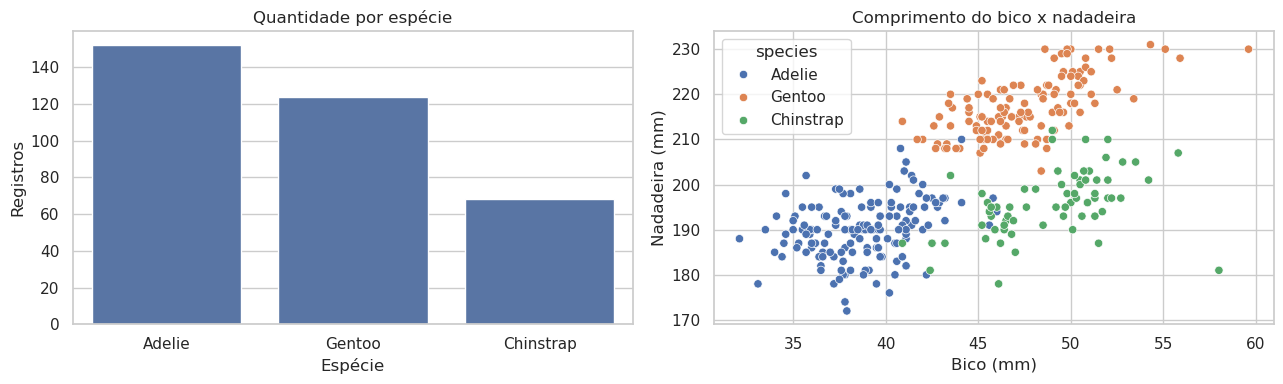

In [6]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))

sns.countplot(data=df, x="species", ax=eixos[0], order=df["species"].value_counts().index)
eixos[0].set(title="Quantidade por espécie", xlabel="Espécie", ylabel="Registros")

sns.scatterplot(
    data=df,
    x="bill_length_mm",
    y="flipper_length_mm",
    hue="species",
    ax=eixos[1],
)
eixos[1].set(title="Comprimento do bico x nadadeira", xlabel="Bico (mm)", ylabel="Nadadeira (mm)")

plt.tight_layout()
plt.show()

## 3. Transformação nas colunas

Criamos o atributo `proporcao_bico` (comprimento / altura do bico), que resume a forma do bico em um único número e ajuda a separar as espécies.

Além disso, o `ColumnTransformer` aplica, de forma automática e sem vazamento de dados:

- **Colunas numéricas:** imputação pela mediana e padronização (`StandardScaler`).
- **Colunas categóricas:** imputação pela moda e codificação one-hot (`OneHotEncoder`).

O alvo (`species`) não sofre transformação: é a classe a ser prevista.

In [7]:
df["proporcao_bico"] = df["bill_length_mm"] / df["bill_depth_mm"]

COLUNAS_NUMERICAS = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g",
    "proporcao_bico",
]
COLUNAS_CATEGORICAS = ["island", "sex"]

pre_processamento = ColumnTransformer(
    transformers=[
        ("numericas", StandardScaler(), COLUNAS_NUMERICAS),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), COLUNAS_CATEGORICAS),
    ]
)

display(df[["bill_length_mm", "bill_depth_mm", "proporcao_bico"]].head())
print("Colunas transformadas:", COLUNAS_NUMERICAS + COLUNAS_CATEGORICAS)

,bill_length_mm,bill_depth_mm,proporcao_bico
0,39.1,18.7,2.090909
1,39.5,17.4,2.270115
2,40.3,18.0,2.238889
3,NaN,NaN,NaN
4,36.7,19.3,1.901554


Colunas transformadas: ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'proporcao_bico', 'island', 'sex']


## 4. Transformação nas linhas

Removemos as linhas com valores ausentes e as linhas duplicadas. Essa operação atua sobre as **linhas** do conjunto (e não sobre colunas), eliminando registros que não podem ser usados para o treinamento supervisionado.

In [8]:
linhas_antes = len(df)
df = df.dropna().drop_duplicates().reset_index(drop=True)
linhas_removidas = linhas_antes - len(df)

print(f"Linhas antes: {linhas_antes}")
print(f"Linhas removidas: {linhas_removidas}")
print(f"Linhas depois: {len(df)}")
print("Valores ausentes restantes:", int(df.isna().sum().sum()))

display(df.head())

Linhas antes: 344
Linhas removidas: 11
Linhas depois: 333
Valores ausentes restantes: 0


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,proporcao_bico
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2.090909
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2.270115
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2.238889
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,1.901554
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,1.907767


## 5. Conjuntos de treino, validação e teste

A divisão é estratificada para preservar a proporção das três espécies em cada subconjunto:

- **Treino:** 60% dos dados — ajuste dos modelos.
- **Validação:** 20% dos dados — escolha do modelo.
- **Teste:** 20% dos dados — avaliação final, usada uma única vez.

In [9]:
X = df.drop(columns="species")
y = df["species"]

X_treino_val, X_teste, y_treino_val, y_teste = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
X_treino, X_validacao, y_treino, y_validacao = train_test_split(
    X_treino_val, y_treino_val, test_size=0.25, stratify=y_treino_val, random_state=RANDOM_STATE
)

resumo = pd.DataFrame(
    {
        "treino": [len(X_treino)],
        "validacao": [len(X_validacao)],
        "teste": [len(X_teste)],
    },
    index=["registros"],
)
display(resumo)

proporcoes = pd.DataFrame(
    {
        "treino": y_treino.value_counts(normalize=True),
        "validacao": y_validacao.value_counts(normalize=True),
        "teste": y_teste.value_counts(normalize=True),
    }
).round(3)
display(proporcoes)

,treino,validacao,teste
registros,199,67,67


,treino,validacao,teste
species,,,
Adelie,0.442,0.433,0.433
Gentoo,0.357,0.358,0.358
Chinstrap,0.201,0.209,0.209


## 6. Treinamento e avaliação dos modelos

Treinos dois classificadores (Regressão Logística e Floresta Aleatória) apenas com o conjunto de treino. A **validação** define qual modelo segue para a etapa final; em seguida, o vencedor é reajustado com treino + validação antes de ser avaliado no teste.

In [10]:
candidatos = {
    "Regressao Logistica": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Floresta Aleatoria": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
}

pipelines = {}
resultados_validacao = {}

for nome, estimador in candidatos.items():
    pipeline = Pipeline([("pre", clone(pre_processamento)), ("modelo", clone(estimador))])
    pipeline.fit(X_treino, y_treino)
    pipelines[nome] = pipeline
    resultados_validacao[nome] = accuracy_score(y_validacao, pipeline.predict(X_validacao))

display(pd.DataFrame.from_dict(resultados_validacao, orient="index", columns=["acuracia_validacao"]).round(4))

melhor_nome = max(resultados_validacao, key=resultados_validacao.get)
modelo_final = pipelines[melhor_nome]
print(f"Modelo escolhido na validação: {melhor_nome}")

,acuracia_validacao
Regressao Logistica,1.0
Floresta Aleatoria,1.0


Modelo escolhido na validação: Regressao Logistica


In [11]:
X_treino_final = pd.concat([X_treino, X_validacao])
y_treino_final = pd.concat([y_treino, y_validacao])

modelo_final.fit(X_treino_final, y_treino_final)
print("Modelo final reajustado com treino + validação.")

Modelo final reajustado com treino + validação.


## 7. Matriz de confusão e acurácia no teste

Avaliação final no conjunto de teste, que não participou do treino nem da escolha do modelo.

In [12]:
y_previsto = modelo_final.predict(X_teste)
acuracia_teste = accuracy_score(y_teste, y_previsto)

print(f"Acurácia no teste: {acuracia_teste:.2%}")
print()
print(classification_report(y_teste, y_previsto))

Acurácia no teste: 100.00%

              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        29
   Chinstrap       1.00      1.00      1.00        14
      Gentoo       1.00      1.00      1.00        24

    accuracy                           1.00        67
   macro avg       1.00      1.00      1.00        67
weighted avg       1.00      1.00      1.00        67



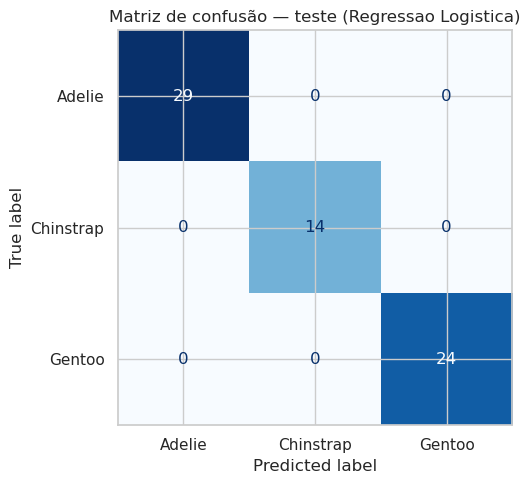

In [13]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_teste,
    y_previsto,
    display_labels=sorted(y.unique()),
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title(f"Matriz de confusão — teste ({melhor_nome})")
plt.tight_layout()
plt.show()

## 8. Modelo implantado — predição de um novo exemplo

O pipeline ajustado é salvo em disco com `joblib` e carregado novamente, simulando o carregamento de um modelo em produção. Em seguida, uma nova observação é classificada pelo modelo implantado.

In [14]:
MODELO_PATH = Path("models/modelo_penguins.joblib")
MODELO_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(modelo_final, MODELO_PATH)

modelo_implantado = joblib.load(MODELO_PATH)
print(f"Modelo implantado carregado de: {MODELO_PATH}")

Modelo implantado carregado de: models/modelo_penguins.joblib


In [15]:
novo_pinguim = pd.DataFrame(
    [
        {
            "island": "Biscoe",
            "bill_length_mm": 46.5,
            "bill_depth_mm": 14.8,
            "flipper_length_mm": 220,
            "body_mass_g": 5050,
            "sex": "male",
        }
    ]
)
novo_pinguim["proporcao_bico"] = (
    novo_pinguim["bill_length_mm"] / novo_pinguim["bill_depth_mm"]
)

classe_prevista = modelo_implantado.predict(novo_pinguim)[0]
probabilidades = modelo_implantado.predict_proba(novo_pinguim)[0]
confianca = probabilidades.max()

print("Nova observação:")
display(novo_pinguim)
print(f"Espécie prevista pelo modelo implantado: {classe_prevista}")
print(f"Confiança: {confianca:.2%}")
display(
    pd.DataFrame(
        {"probabilidade": probabilidades},
        index=modelo_implantado.classes_,
    ).round(4)
)

Nova observação:


,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,proporcao_bico
0,Biscoe,46.5,14.8,220,5050,male,3.141892


Espécie prevista pelo modelo implantado: Gentoo
Confiança: 99.78%


,probabilidade
Adelie,0.0008
Chinstrap,0.0013
Gentoo,0.9978


## 9. Resumo da esteira executada

| Etapa do PDF | Onde foi atendida |
| --- | --- |
| Base de classificação do Kaggle | Seção 1 (Palmer Penguins) |
| Estatísticas descritivas gerais | Seção 2 |
| Transformação em colunas | Seção 3 (`proporcao_bico`, one-hot, scaling) |
| Transformação em linhas | Seção 4 (`dropna` + `drop_duplicates`) |
| Treino, validação e teste | Seção 5 (60/20/20 estratificado) |
| Treinamento e avaliação | Seções 6 e 7 |
| Matriz de confusão e acurácia | Seção 7 |
| Predição do modelo implantado | Seção 8 (`joblib` + nova observação) |